In [3]:
import pandas as pd

customers = pd.read_csv("Data/customer_info.csv")
usage = pd.read_csv("Data/usage_data.csv")
churn = pd.read_csv("Data/churn_labels.csv")

In [4]:
print("Customer data:",customers.shape)
print("Usage data:",usage.shape)
print("Chrun data",churn.shape)

Customer data: (10200, 7)
Usage data: (120000, 6)
Chrun data (10000, 2)


In [5]:
print("CUSTOMER COLUMNS:")
print(customers.columns.tolist())

print("\nUSAGE COLUMNS:")
print(usage.columns.tolist())

print("\nCHURN COLUMNS:")
print(churn.columns.tolist())

CUSTOMER COLUMNS:
['CustomerID', 'Age', 'Gender', 'Region', 'ContractType', 'MonthlyCharges', 'SignupDate']

USAGE COLUMNS:
['CustomerID', 'Month', 'CallMinutes', 'DataUsageGB', 'SMSCount', 'Complaints']

CHURN COLUMNS:
['CustomerID', 'Churn']


In [6]:
display(customers.head())
display(usage.head())
display(churn.head())

,CustomerID,Age,Gender,Region,ContractType,MonthlyCharges,SignupDate
0,CUST_0,NaN,Male,Urban,Yearly,48.18,2021-03-20
1,CUST_1,NaN,Female,Suburban,Prepaid,38.94,2020-01-25
2,CUST_2,46.0,Female,Rural,Monthly,48.56,2022-08-31
3,CUST_3,NaN,Female,Urban,Prepaid,24.22,2018-12-09
4,CUST_4,60.0,Male,Rural,Monthly,67.86,2022-12-28


,CustomerID,Month,CallMinutes,DataUsageGB,SMSCount,Complaints
0,CUST_0,2023-01-31,518.12,7.21,9,1
1,CUST_0,2023-02-28,439.79,5.99,35,1
2,CUST_0,2023-03-31,545.06,14.16,14,1
3,CUST_0,2023-04-30,461.78,6.66,40,0
4,CUST_0,2023-05-31,434.82,12.75,26,2


,CustomerID,Churn
0,CUST_0,0
1,CUST_1,0
2,CUST_2,0
3,CUST_3,0
4,CUST_4,0


In [7]:
# Check missing values in each dataset

print("CUSTOMER DATA — Missing Values")
print(customers.isna().sum())

print("\nUSAGE DATA — Missing Values")
print(usage.isna().sum())

print("\nCHURN DATA — Missing Values")
print(churn.isna().sum())

CUSTOMER DATA — Missing Values
CustomerID           0
Age               3583
Gender               0
Region               0
ContractType         0
MonthlyCharges       0
SignupDate           0
dtype: int64

USAGE DATA — Missing Values
CustomerID     0
Month          0
CallMinutes    0
DataUsageGB    0
SMSCount       0
Complaints     0
dtype: int64

CHURN DATA — Missing Values
CustomerID    0
Churn         0
dtype: int64


In [8]:
# Count duplicate rows

print("Customer duplicate rows:", customers.duplicated().sum())
print("Usage duplicate rows:", usage.duplicated().sum())
print("Churn duplicate rows:", churn.duplicated().sum())

# Check duplicate customer IDs
print("\nDuplicate customer IDs in customer data:",
      customers["CustomerID"].duplicated().sum())

print("Duplicate customer IDs in churn data:",
      churn["CustomerID"].duplicated().sum())

Customer duplicate rows: 195
Usage duplicate rows: 0
Churn duplicate rows: 0

Duplicate customer IDs in customer data: 200
Duplicate customer IDs in churn data: 0


In [9]:
# Count unique customers in each dataset

print("Unique customers:", customers["CustomerID"].nunique())
print("Unique usage customers:", usage["CustomerID"].nunique())
print("Unique churn customers:", churn["CustomerID"].nunique())

# Check IDs without a matching churn label
missing_churn_ids = set(customers["CustomerID"]) - set(churn["CustomerID"])

print("\nCustomers without churn labels:", len(missing_churn_ids))
print("Sample IDs:", list(missing_churn_ids)[:10])

Unique customers: 10000
Unique usage customers: 10000
Unique churn customers: 10000

Customers without churn labels: 0
Sample IDs: []


In [10]:
#Find all rows with duplicated customerIDs
duplicate_customers = customers[
    customers.duplicated(subset="CustomerID",keep = False)
].sort_values("CustomerID")

display(duplicate_customers.head(20))

,CustomerID,Age,Gender,Region,ContractType,MonthlyCharges,SignupDate
1031,CUST_1031,57.0,Male,Urban,Monthly,40.60,2023-05-23
10070,CUST_1031,57.0,Male,Urban,Monthly,40.60,2023-05-23
1042,CUST_1042,NaN,Male,Urban,Monthly,63.09,2021-04-24
10075,CUST_1042,NaN,Male,Urban,Monthly,63.09,2021-04-24
10061,CUST_1128,55.0,Male,Urban,Prepaid,31.88,2019-01-18
1128,CUST_1128,55.0,Male,Urban,Prepaid,31.88,2019-01-18
1134,CUST_1134,NaN,Male,Suburban,Yearly,55.07,2019-02-18
10195,CUST_1134,NaN,Male,Suburban,Yearly,55.07,2019-02-18
1228,CUST_1228,NaN,Male,Suburban,Yearly,25.77,2023-01-05
10143,CUST_1228,NaN,Male,Suburban,Yearly,25.77,2023-01-05


In [11]:
# Check whether duplicated customer IDs have identical records

duplicate_rows = customers[
    customers.duplicated(subset="CustomerID", keep=False)
]

duplicate_groups = duplicate_rows.groupby("CustomerID")

conflicting_ids = []

for customer_id, group in duplicate_groups:
    if len(group.drop_duplicates()) > 1:
        conflicting_ids.append(customer_id)

print("Customer IDs with conflicting records:", len(conflicting_ids))
print("Sample conflicting IDs:", conflicting_ids[:10])

Customer IDs with conflicting records: 5
Sample conflicting IDs: ['CUST_248', 'CUST_308', 'CUST_333', 'CUST_391', 'CUST_466']


In [12]:
# Inspect customer IDs with conflicting records

conflicting_customers = customers[
    customers["CustomerID"].isin(conflicting_ids)
].sort_values("CustomerID")

display(conflicting_customers)

,CustomerID,Age,Gender,Region,ContractType,MonthlyCharges,SignupDate
248,CUST_248,22.0,Male,Rural,Monthly,58.85,2022-09-06
10024,CUST_248,22.0,Male,Rural,Monthly,58.85,2022-06-09
308,CUST_308,37.0,Male,Urban,Monthly,42.28,2018-01-03
10144,CUST_308,37.0,Male,Urban,Monthly,42.28,2018-03-01
333,CUST_333,NaN,Male,Rural,Prepaid,63.64,2023-11-02
10089,CUST_333,NaN,Male,Rural,Prepaid,63.64,2023-02-11
391,CUST_391,NaN,Female,Urban,Yearly,31.60,2023-11-03
10150,CUST_391,NaN,Female,Urban,Yearly,31.60,2023-03-11
466,CUST_466,23.0,Female,Urban,Monthly,45.18,2021-03-07
10076,CUST_466,23.0,Female,Urban,Monthly,45.18,2021-07-03


In [13]:
# Separate conflicting customer records for investigation

conflicting_ids = [
    "CUST_248",
    "CUST_308",
    "CUST_333",
    "CUST_391",
    "CUST_466"
]

# Keep conflicting records separate
conflicting_customers = customers[
    customers["CustomerID"].isin(conflicting_ids)
].copy()

# Remove exact duplicate rows only
customers_clean = customers.drop_duplicates().copy()

print("Original rows:", len(customers))
print("Rows after removing exact duplicates:", len(customers_clean))
print("Unique customer IDs remaining:",
      customers_clean["CustomerID"].nunique())
print("Conflicting customer IDs:",
      conflicting_customers["CustomerID"].nunique())

Original rows: 10200
Rows after removing exact duplicates: 10005
Unique customer IDs remaining: 10000
Conflicting customer IDs: 5


In [14]:

# Check whether duplicate CustomerIDs still exist

print(
    "Duplicate customer IDs remaining:",
    customers_clean["CustomerID"].duplicated().sum()
)


Duplicate customer IDs remaining: 5


In [15]:
# Clean exact duplicates and flag conflicting signup dates

customers_clean = customers.drop_duplicates().copy()

conflicting_ids = [
    "CUST_248",
    "CUST_308",
    "CUST_333",
    "CUST_391",
    "CUST_466"
]

# Set uncertain signup dates to missing
customers_clean.loc[
    customers_clean["CustomerID"].isin(conflicting_ids),
    "SignupDate"
] = pd.NaT

# Keep only one record per customer after flagging date conflicts
customers_clean = customers_clean.drop_duplicates(
    subset="CustomerID",
    keep="first"
).copy()

print("Rows after cleaning:", len(customers_clean))
print("Unique customers:", customers_clean["CustomerID"].nunique())
print("Duplicate customer IDs remaining:",
      customers_clean["CustomerID"].duplicated().sum())
print("Signup dates flagged as uncertain:",
      customers_clean["SignupDate"].isna().sum())

Rows after cleaning: 10000
Unique customers: 10000
Duplicate customer IDs remaining: 0
Signup dates flagged as uncertain: 5


In [16]:
print("Missing values in a cleaned customer data:",customers_clean.isna().sum())

Missing values in a cleaned customer data: CustomerID           0
Age               3500
Gender               0
Region               0
ContractType         0
MonthlyCharges       0
SignupDate           5
dtype: int64


In [17]:
# Check missing ages by customer group

print("Missing ages by gender:")
print(customers_clean.groupby("Gender")["Age"].apply(
    lambda x: x.isna().sum()
))

print("\nMissing ages by region:")
print(customers_clean.groupby("Region")["Age"].apply(
    lambda x: x.isna().sum()
))

print("\nMissing ages by contract type:")
print(customers_clean.groupby("ContractType")["Age"].apply(
    lambda x: x.isna().sum()
))

Missing ages by gender:
Gender
Female    1803
Male      1697
Name: Age, dtype: int64

Missing ages by region:
Region
Rural       1149
Suburban    1201
Urban       1150
Name: Age, dtype: int64

Missing ages by contract type:
ContractType
Monthly    1367
Prepaid    1431
Yearly      702
Name: Age, dtype: int64


In [18]:
# Check how many customers churned

print("Churn distribution:")
print(churn["Churn"].value_counts())

print("\nChurn percentage:")
print((churn["Churn"].value_counts(normalize=True) * 100).round(2))


Churn distribution:
Churn
0    9214
1     786
Name: count, dtype: int64

Churn percentage:
Churn
0    92.14
1     7.86
Name: proportion, dtype: float64


In [19]:
# Combine customer information with churn labels

customer_analysis = customers_clean.merge(
    churn,
    on= "CustomerID",
    how="left"
)

# Calculate churn rate for each customer type
contract_churn = customer_analysis.groupby("ContractType")["Churn"].agg(
    ["count","sum","mean"]
)

contract_churn.columns = [
    "Total_Customers",
    "Customers_Churned",
    "Churn_Rate"
]
contract_churn["Churn_Rate"] = (
    contract_churn["Churn_Rate"] * 100
).round(2)

display(contract_churn)

,Total_Customers,Customers_Churned,Churn_Rate
ContractType,,,
Monthly,3953,299,7.56
Prepaid,4041,310,7.67
Yearly,2006,177,8.82


In [20]:
# Summarize usage for each customer

customer_usage = usage.groupby("CustomerID").agg(
    Total_CallMinutes=("CallMinutes", "sum"),
    Total_DataUsageGB=("DataUsageGB", "sum"),
    Total_SMS=("SMSCount", "sum"),
    Total_Complaints=("Complaints", "sum")
).reset_index()

# Combine customer usage with churn labels

usage_churn = customer_usage.merge(
    churn,
    on="CustomerID",
    how="left"
)

# Compare average complaints for customers who stayed vs churned

complaint_analysis = usage_churn.groupby("Churn").agg(
    Customers=("CustomerID", "count"),
    Average_Complaints=("Total_Complaints", "mean")
)

display(complaint_analysis.round(2))

,Customers,Average_Complaints
Churn,,
0,9214,6.02
1,786,6.17


In [21]:
# Compare average usage for customers who stayed vs churned

usage_comparison = usage_churn.groupby("Churn").agg(
    Average_CallMinutes=("Total_CallMinutes", "mean"),
    Average_DataUsageGB=("Total_DataUsageGB", "mean"),
    Average_SMS=("Total_SMS", "mean"),
    Average_Complaints=("Total_Complaints", "mean")
)

usage_comparison.index = ["Stayed", "Churned"]

display(usage_comparison.round(2))

,Average_CallMinutes,Average_DataUsageGB,Average_SMS,Average_Complaints
Stayed,5906.34,118.8,293.98,6.02
Churned,5937.93,118.5,298.13,6.17


In [22]:
# Analyze churn by region

region_analysis = customer_analysis.groupby("Region").agg(
    Total_Customers=("CustomerID", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

region_analysis["Churn_Rate"] = (
    region_analysis["Churn_Rate"] * 100
).round(2)

display(region_analysis.sort_values("Churn_Rate", ascending=False))

,Total_Customers,Customers_Churned,Churn_Rate
Region,,,
Urban,3287,267,8.12
Suburban,3402,274,8.05
Rural,3311,245,7.40


In [23]:
# Analyze churn by monthly charge groups

customer_analysis["ChargeGroup"] = pd.cut(
    customer_analysis["MonthlyCharges"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

charge_analysis = customer_analysis.groupby(
    "ChargeGroup",
    observed=True
).agg(
    Total_Customers=("CustomerID", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

charge_analysis["Churn_Rate"] = (
    charge_analysis["Churn_Rate"] * 100
).round(2)

display(charge_analysis)

,Total_Customers,Customers_Churned,Churn_Rate
ChargeGroup,,,
Low,9951,783,7.87
Medium,26,0,0.00
High,23,3,13.04


In [24]:
# Inspect the distribution of monthly charges

print(customer_analysis["MonthlyCharges"].describe())

print("\nLowest 10 monthly charges:")
print(customer_analysis["MonthlyCharges"].nsmallest(10).to_list())

print("\nHighest 10 monthly charges:")
print(customer_analysis["MonthlyCharges"].nlargest(10).to_list())

count    10000.000000
mean        51.000240
std         21.543385
min         -6.720000
25%         39.797500
50%         50.015000
75%         60.500000
max        390.300000
Name: MonthlyCharges, dtype: float64

Lowest 10 monthly charges:
[-6.72, -4.55, -3.89, -3.15, -0.46, 0.38, 0.72, 1.12, 2.83, 3.24]

Highest 10 monthly charges:
[390.3, 369.55, 367.65, 356.0, 353.35, 338.1, 329.95, 321.45000000000005, 318.5, 316.8]


In [25]:
# investigate ususal monthly charge values

charges = customer_analysis["MonthlyCharges"]

print("Negative charges:",(charges < 0).sum())
print("Zero charges:",(charges == 0).sum())
print("Charges above 100:",(charges > 100).sum())
print("Chatges above 200:",(charges > 200).sum())
print("Missing charges:",charges.isna().sum())

Negative charges: 5
Zero charges: 0
Charges above 100: 57
Chatges above 200: 38
Missing charges: 0


In [26]:
# Create charge groups using quartiles

customer_analysis["ChargeGroup"] = pd.qcut(
    customer_analysis["MonthlyCharges"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

# Compare churn across charge groups

charge_analysis = customer_analysis.groupby(
    "ChargeGroup",
    observed=True
).agg(
    Total_Customers=("CustomerID", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

charge_analysis["Churn_Rate"] = (
    charge_analysis["Churn_Rate"] * 100
).round(2)

display(charge_analysis)

,Total_Customers,Customers_Churned,Churn_Rate
ChargeGroup,,,
Low,2500,194,7.76
Medium,2500,226,9.04
High,2502,188,7.51
Very High,2498,178,7.13


In [27]:
# Create age groups
customer_analysis["AgeGroup"] = pd.cut(
    customer_analysis["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# Compare churn across age groups
age_analysis = customer_analysis.groupby(
    "AgeGroup",
    observed=True
).agg(
    Total_Customers=("CustomerID", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

age_analysis["Churn_Rate"] = (
    age_analysis["Churn_Rate"] * 100
).round(2)

display(age_analysis)

,Total_Customers,Customers_Churned,Churn_Rate
AgeGroup,,,
18-25,991,74,7.47
26-35,1267,92,7.26
36-45,1293,99,7.66
46-55,1226,108,8.81
56+,1723,133,7.72


In [28]:
# Analyze churn by gender

gender_analysis = customer_analysis.groupby("Gender").agg(
    Total_Customers=("CustomerID", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

gender_analysis["Churn_Rate"] = (
    gender_analysis["Churn_Rate"] * 100
).round(2)

display(gender_analysis)

,Total_Customers,Customers_Churned,Churn_Rate
Gender,,,
Female,5022,387,7.71
Male,4978,399,8.02


In [29]:
# Analyze churn by signup year

customer_analysis["SignupDate"] = pd.to_datetime(
    customer_analysis["SignupDate"],
    errors="coerce"
)

customer_analysis["SignupYear"] = (
    customer_analysis["SignupDate"].dt.year
)

signup_analysis = customer_analysis.groupby("SignupYear").agg(
    Total_Customers=("CustomerID", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

signup_analysis["Churn_Rate"] = (
    signup_analysis["Churn_Rate"] * 100
).round(2)

display(signup_analysis)

,Total_Customers,Customers_Churned,Churn_Rate
SignupYear,,,
2018.0,1873,151,8.06
2019.0,1807,139,7.69
2020.0,1772,130,7.34
2021.0,1824,150,8.22
2022.0,1801,146,8.11
2023.0,918,69,7.52


In [30]:
# Compare churn rates across monthly charge groups

charge_churn = customer_analysis.groupby(
    "ChargeGroup",
    observed=True
).agg(
    Total_Customers=("CustomerID", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

charge_churn["Churn_Rate"] = (
    charge_churn["Churn_Rate"] * 100
).round(2)

display(charge_churn)

,Total_Customers,Customers_Churned,Churn_Rate
ChargeGroup,,,
Low,2500,194,7.76
Medium,2500,226,9.04
High,2502,188,7.51
Very High,2498,178,7.13


In [31]:
# Inspect customers with suspicious monthly charges

suspicious_charges = customer_analysis[
    (customer_analysis["MonthlyCharges"] < 0) |
    (customer_analysis["MonthlyCharges"] > 200)
].sort_values("MonthlyCharges")

display(suspicious_charges[
    ["CustomerID", "MonthlyCharges", "ContractType", "Churn"]
])

print("Number of suspicious records:", len(suspicious_charges))

,CustomerID,MonthlyCharges,ContractType,Churn
8567,CUST_8567,-6.72,Prepaid,0
9403,CUST_9403,-4.55,Monthly,0
4671,CUST_4671,-3.89,Prepaid,0
6820,CUST_6820,-3.15,Yearly,0
5575,CUST_5575,-0.46,Monthly,0
9791,CUST_9791,202.00,Monthly,0
424,CUST_424,207.95,Prepaid,0
4504,CUST_4504,211.35,Monthly,0
5068,CUST_5068,211.90,Monthly,0
1830,CUST_1830,217.40,Monthly,0


Number of suspicious records: 43


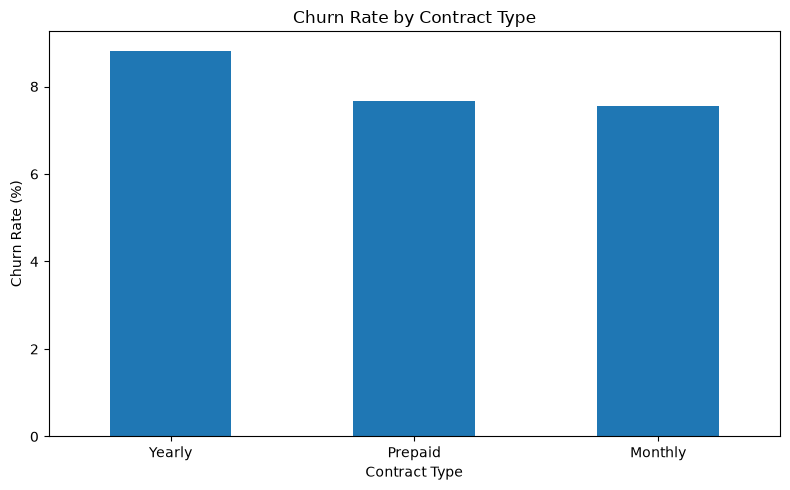

In [32]:
import matplotlib.pyplot as plt

# Plot churn rate by contract type
contract_plot = contract_churn["Churn_Rate"].sort_values(
    ascending=False
)

contract_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

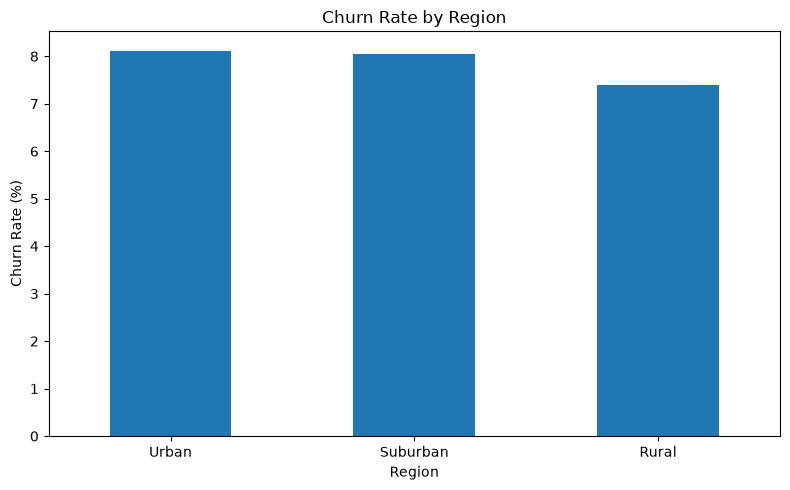

In [33]:
# Plot churn rate by region

region_plot = region_analysis["Churn_Rate"].sort_values(
    ascending=False
)

region_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Churn Rate by Region")
plt.xlabel("Region")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

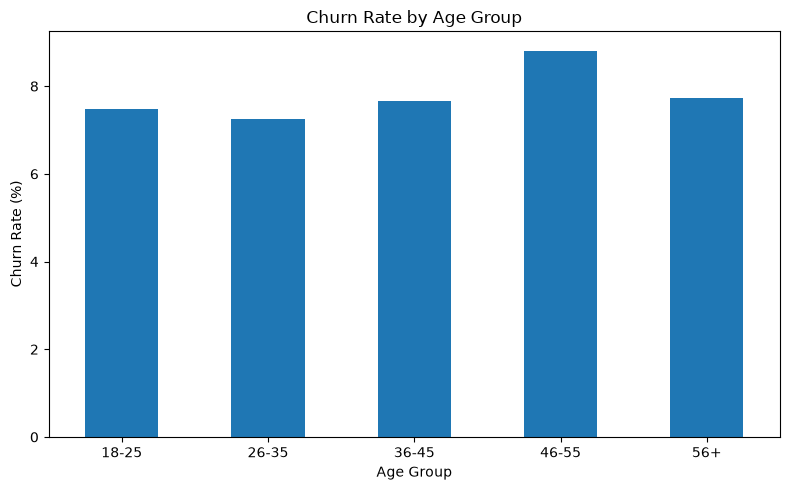

In [34]:
# Plot churn rate by age group

age_plot = age_analysis["Churn_Rate"]

age_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Key Findings — Customer Churn Analysis

1. **Overall churn:** 7.86% of customers churned (786 out of 10,000).
2. **Contract type:** Yearly customers had the highest observed churn rate at 8.82%.
3. **Region:** Urban customers had a churn rate of 8.12%, compared with 7.40% for Rural customers.
4. **Age group:** Customers aged 46–55 had the highest observed churn rate at 8.81%. However, 3,500 customers had missing age data.
5. **Gender:** Male customers had a churn rate of 8.02%, compared with 7.71% for female customers. The difference was small.
6. **Customer complaints:** Churned customers averaged 6.17 complaints, compared with 6.02 among customers who stayed.
7. **Data quality:** Five customers had negative monthly charges, and unusually high charges require further validation. Five conflicting signup dates were also marked as uncertain.

### Important limitation

These are descriptive findings, not proof of cause and effect. The observed differences should be validated before making business decisions.

In [35]:
# Check the datasets we plan to export

print("Clean customers:", customers_clean.shape)
print("Usage data:", usage.shape)
print("Churn labels:", churn.shape)
print("Customer analysis:", customer_analysis.shape)

print("\nDuplicate customer IDs:",
      customers_clean["CustomerID"].duplicated().sum())

print("Missing churn labels:",
      customer_analysis["Churn"].isna().sum())

Clean customers: (10000, 7)
Usage data: (120000, 6)
Churn labels: (10000, 2)
Customer analysis: (10000, 11)

Duplicate customer IDs: 0
Missing churn labels: 0


In [36]:
# Export cleaned datasets for SQL and Power BI

from pathlib import Path

export_folder = Path("Data/cleaned")
export_folder.mkdir(parents=True, exist_ok=True)

customers_clean.to_csv(
    export_folder / "customers_clean.csv", index=False
)

usage.to_csv(
    export_folder / "usage.csv", index=False
)

churn.to_csv(
    export_folder / "churn_labels.csv", index=False
)

customer_analysis.to_csv(
    export_folder / "customer_analysis.csv", index=False
)

print("All four datasets exported successfully.")

All four datasets exported successfully.
